# tile-math on real data: which web-map tiles cover Egypt?

Question: how many Web Mercator XYZ tiles are needed to cover Egypt at zoom 5-9, and how many of the tiles in its bounding box actually hold Egypt?

Data: Egypt's border from Natural Earth 1:50m (public domain), `data/egypt.geojson`. Coordinates are lon/lat (x first), EPSG:4326.

In [1]:
import sys
from pathlib import Path

here = Path.cwd()
if not (here / 'make_showcase.py').exists():
    here = here / 'showcase'
sys.path.insert(0, str(here))
import make_showcase as ms
from tile_math import bbox_to_tiles, lonlat_to_tile, tile_to_quadkey

ring = ms.load_egypt(here / 'data')
print(len(ring), 'border vertices (lon, lat), first:', ring[0])

253 border vertices (lon, lat), first: (36.8714, 21.9967)


## Bounding box and a single point

Cairo (31.2357 E, 30.0444 N) sits in one tile per zoom.

In [2]:
west, south, east, north = ms.ring_bbox(ring)
print('bbox (west, south, east, north):', west, south, east, north)
x, y, z = lonlat_to_tile(31.2357, 30.0444, 8)
print('Cairo at zoom 8:', (x, y, z), 'quadkey', tile_to_quadkey(x, y, z))
print('tiles in bbox at zoom 8:', len(bbox_to_tiles(west, south, east, north, 8)))

bbox (west, south, east, north): 24.7032 21.9949 36.8714 31.655
Cairo at zoom 8: (150, 105, 8) quadkey 12212112
tiles in bbox at zoom 8: 80


## Classify tiles

A tile is `border` if a border segment passes through its interior (exact segment/rectangle clipping, no sampling). Any other tile lies wholly inside or wholly outside Egypt, so its centre decides: `interior` if inside, otherwise `outside`.

In [3]:
from collections import Counter
from IPython.display import Markdown, display

def md(rows):
    cols = list(rows[0])
    lines = ['| ' + ' | '.join(cols) + ' |', '|' + '---|' * len(cols)]
    lines += ['| ' + ' | '.join(str(r[c]) for c in cols) + ' |' for r in rows]
    return Markdown('\n'.join(lines))

display(md(ms.summary(ring)))

| zoom | bbox_tiles | border | interior | needed | needed_share |
|---|---|---|---|---|---|
| 5 | 2 | 2 | 0 | 2 | 1.0 |
| 6 | 6 | 6 | 0 | 6 | 1.0 |
| 7 | 24 | 16 | 5 | 21 | 0.875 |
| 8 | 80 | 34 | 34 | 68 | 0.85 |
| 9 | 288 | 74 | 162 | 236 | 0.819 |

In [4]:
fc = ms.build_geojson(ring)
counts = Counter(f['properties']['status'] for f in fc['features'] if f['properties']['kind'] == 'tile')
display(md([{'status': k, 'tiles': v} for k, v in sorted(counts.items())]))

| status | tiles |
|---|---|
| border | 34 |
| interior | 34 |
| outside | 12 |

## Map (zoom 8)

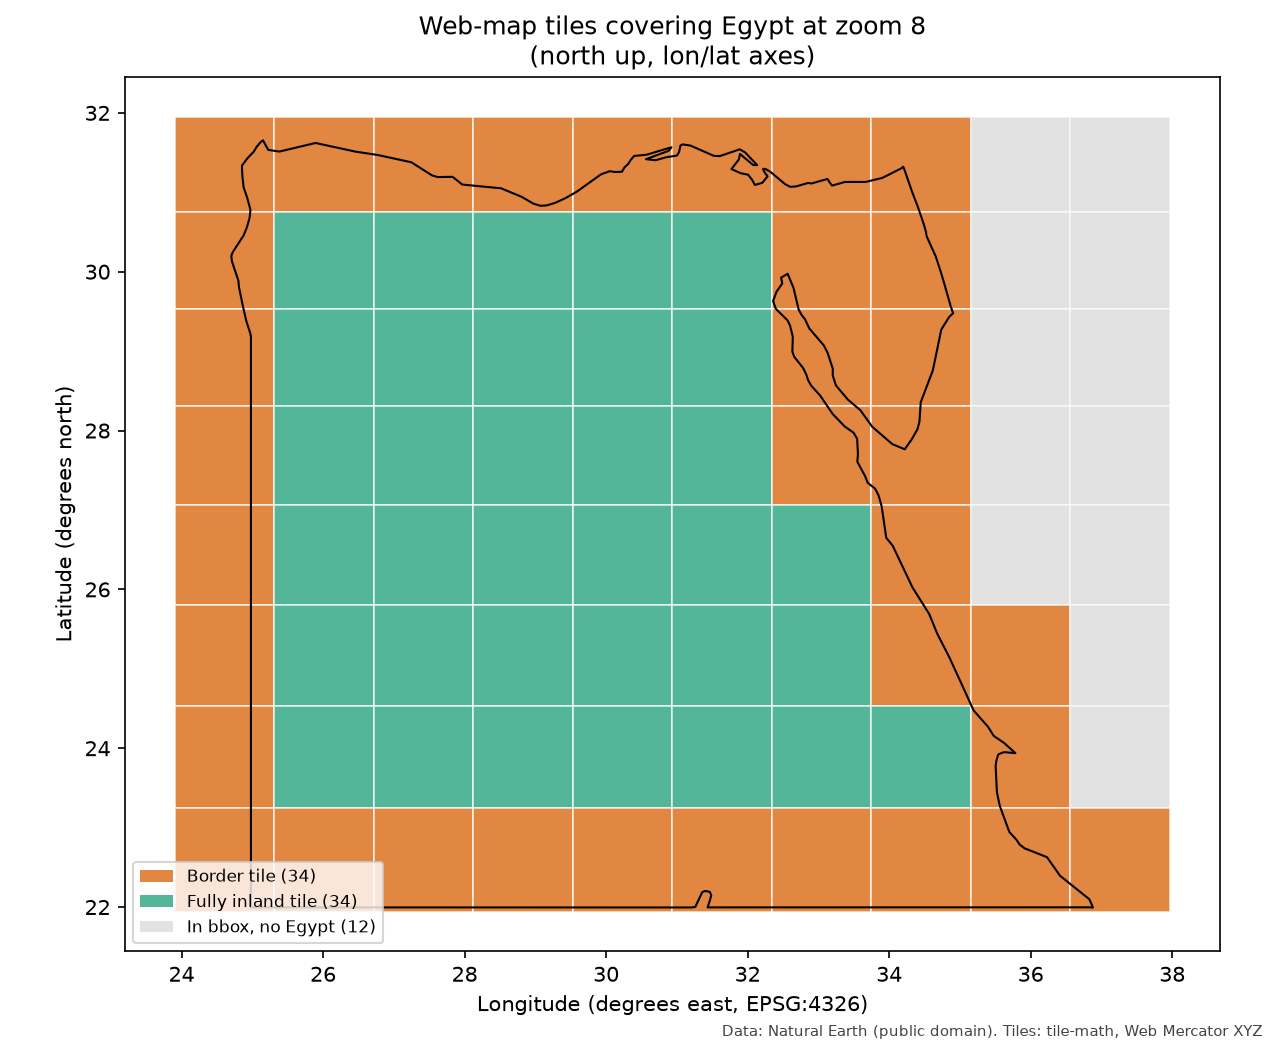

In [5]:
import matplotlib
matplotlib.use('Agg')
from IPython.display import Image, display
import tempfile

# draw_map renders the same figure as map.png
with tempfile.TemporaryDirectory() as tmp:
    ms.draw_map(fc, Path(tmp) / 'map.png', ring)
    display(Image(filename=str(Path(tmp) / 'map.png'), width=800))